In [1]:
#View current kernel
import sys
print(sys.executable)

C:\Users\DELL\anaconda3\python.exe


In [2]:
!pip --version

pip 26.1.2 from C:\Users\DELL\anaconda3\Lib\site-packages\pip (python 3.13)



In [3]:
#!pip install pandas numpy matplotlib shap

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
raw_mmm_data = pd.read_csv("../data/conjura_mmm_data.csv")
##Copy file to prevent original dataset loss 
mmm_data = raw_mmm_data.copy()
mmm_data.head()

,MMM_TIMESERIES_ID,ORGANISATION_ID,ORGANISATION_VERTICAL,ORGANISATION_SUBVERTICAL,ORGANISATION_MARKETING_SOURCES,ORGANISATION_PRIMARY_TERRITORY_NAME,TERRITORY_NAME,DATE_DAY,CURRENCY_CODE,FIRST_PURCHASES,...,META_FACEBOOK_IMPRESSIONS,META_INSTAGRAM_IMPRESSIONS,META_OTHER_IMPRESSIONS,TIKTOK_IMPRESSIONS,DIRECT_CLICKS,BRANDED_SEARCH_CLICKS,ORGANIC_SEARCH_CLICKS,EMAIL_CLICKS,REFERRAL_CLICKS,ALL_OTHER_CLICKS
0,596eef7c71f933d820d0e485935d0e8f,04769dac8b828ec7a85676d9e2bffe6f,Beauty & Fitness,Hair Care,"Google, Meta",US,All Territories,2022-07-29,USD,22,...,18997.0,NaN,NaN,NaN,139.0,NaN,300.0,1.0,61.0,40.0
1,596eef7c71f933d820d0e485935d0e8f,04769dac8b828ec7a85676d9e2bffe6f,Beauty & Fitness,Hair Care,"Google, Meta",US,All Territories,2022-07-30,USD,14,...,20188.0,NaN,NaN,NaN,209.0,NaN,442.0,8.0,110.0,62.0
2,596eef7c71f933d820d0e485935d0e8f,04769dac8b828ec7a85676d9e2bffe6f,Beauty & Fitness,Hair Care,"Google, Meta",US,All Territories,2022-07-31,USD,31,...,24718.0,NaN,NaN,NaN,262.0,NaN,427.0,631.0,108.0,65.0
3,596eef7c71f933d820d0e485935d0e8f,04769dac8b828ec7a85676d9e2bffe6f,Beauty & Fitness,Hair Care,"Google, Meta",US,All Territories,2022-08-01,USD,18,...,25076.0,NaN,NaN,NaN,247.0,NaN,400.0,117.0,125.0,68.0
4,596eef7c71f933d820d0e485935d0e8f,04769dac8b828ec7a85676d9e2bffe6f,Beauty & Fitness,Hair Care,"Google, Meta",US,All Territories,2022-08-02,USD,23,...,22688.0,NaN,NaN,NaN,255.0,NaN,425.0,37.0,146.0,65.0


In [6]:
##Data Overview
mmm_data.shape

(132759, 50)

In [7]:
mmm_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 132759 entries, 0 to 132758
Data columns (total 50 columns):
 #   Column                               Non-Null Count   Dtype  
---  ------                               --------------   -----  
 0   MMM_TIMESERIES_ID                    132759 non-null  object 
 1   ORGANISATION_ID                      132759 non-null  object 
 2   ORGANISATION_VERTICAL                124649 non-null  object 
 3   ORGANISATION_SUBVERTICAL             124649 non-null  object 
 4   ORGANISATION_MARKETING_SOURCES       132759 non-null  object 
 5   ORGANISATION_PRIMARY_TERRITORY_NAME  132759 non-null  object 
 6   TERRITORY_NAME                       132759 non-null  object 
 7   DATE_DAY                             132759 non-null  object 
 8   CURRENCY_CODE                        132759 non-null  object 
 9   FIRST_PURCHASES                      132759 non-null  int64  
 10  FIRST_PURCHASES_UNITS                132759 non-null  int64  
 11  FIRST_PURCHAS

In [8]:
#Descriptive Stats
mmm_data.describe()

,FIRST_PURCHASES,FIRST_PURCHASES_UNITS,FIRST_PURCHASES_ORIGINAL_PRICE,FIRST_PURCHASES_GROSS_DISCOUNT,ALL_PURCHASES,ALL_PURCHASES_UNITS,ALL_PURCHASES_ORIGINAL_PRICE,ALL_PURCHASES_GROSS_DISCOUNT,GOOGLE_PAID_SEARCH_SPEND,GOOGLE_SHOPPING_SPEND,...,META_FACEBOOK_IMPRESSIONS,META_INSTAGRAM_IMPRESSIONS,META_OTHER_IMPRESSIONS,TIKTOK_IMPRESSIONS,DIRECT_CLICKS,BRANDED_SEARCH_CLICKS,ORGANIC_SEARCH_CLICKS,EMAIL_CLICKS,REFERRAL_CLICKS,ALL_OTHER_CLICKS
count,132759.000000,1.327590e+05,1.327590e+05,1.327590e+05,132759.000000,1.327590e+05,1.327590e+05,1.327590e+05,96637.000000,78980.000000,...,8.011200e+04,2.681700e+04,2.354500e+04,3462.000000,98541.000000,88825.000000,122702.000000,118663.000000,121737.000000,121778.000000
mean,83.857599,5.193310e+02,6.462644e+04,5.094456e+03,124.536845,1.291123e+03,1.186526e+05,1.215327e+04,416.082224,837.683294,...,9.754821e+04,6.584053e+04,1.724004e+03,43198.584922,580.888473,309.502449,569.754218,357.539284,255.566106,680.092472
std,345.347969,5.033012e+03,6.148369e+05,5.541766e+04,1496.001905,1.291308e+04,1.211315e+06,1.395501e+05,2519.605821,3628.118892,...,1.846109e+05,1.273965e+05,2.913215e+04,58713.550984,1046.358097,670.680758,1190.888629,944.721232,817.485088,2331.667413
min,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,1.000000,1.000000e+00,3.490000e+00,0.000000e+00,0.000000,0.000000,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,14.000000,2.400000e+01,1.709675e+03,4.050000e+01,19.000000,3.400000e+01,2.546000e+03,6.994500e+01,15.240000,61.330000,...,9.420750e+03,3.400000e+03,1.300000e+01,4042.250000,93.000000,38.000000,94.000000,20.000000,19.000000,69.000000
50%,33.000000,6.600000e+01,5.262000e+03,1.950000e+02,49.000000,1.060000e+02,7.542000e+03,3.137500e+02,61.400000,245.950000,...,3.065900e+04,1.956700e+04,7.800000e+01,16886.000000,236.000000,116.000000,217.000000,72.000000,58.000000,205.000000
75%,98.000000,2.000000e+02,1.622458e+04,8.570809e+02,141.000000,3.130000e+02,2.319457e+04,1.277665e+03,198.150000,878.360000,...,9.323125e+04,5.888800e+04,4.360000e+02,63467.250000,653.000000,269.000000,574.000000,306.000000,171.000000,572.000000
max,96010.000000,1.000404e+06,7.212126e+07,5.840348e+06,426403.000000,1.000922e+06,1.308895e+08,1.522848e+07,165661.940000,615988.530000,...,3.686852e+06,2.603035e+06,1.325133e+06,349275.000000,29561.000000,22974.000000,125421.000000,46997.000000,32221.000000,298560.000000


**TASK1 - EDA**

In [9]:
#Count missing values
missing_values = mmm_data.isnull().sum().sort_values(ascending=False)
#missing_values
##Display only missing_values where not 0
missing_values = missing_values[missing_values > 0].sort_values(ascending=False)
missing_values

TIKTOK_CLICKS                     129297
TIKTOK_SPEND                      129297
TIKTOK_IMPRESSIONS                129297
GOOGLE_VIDEO_SPEND                125131
GOOGLE_VIDEO_IMPRESSIONS          125131
GOOGLE_VIDEO_CLICKS               125131
GOOGLE_DISPLAY_SPEND              114013
GOOGLE_DISPLAY_CLICKS             114013
GOOGLE_DISPLAY_IMPRESSIONS        114013
META_OTHER_CLICKS                 109214
META_OTHER_IMPRESSIONS            109214
META_OTHER_SPEND                  109214
META_INSTAGRAM_SPEND              105942
META_INSTAGRAM_CLICKS             105942
META_INSTAGRAM_IMPRESSIONS        105942
GOOGLE_PMAX_CLICKS                 71633
GOOGLE_PMAX_SPEND                  71633
GOOGLE_PMAX_IMPRESSIONS            71633
GOOGLE_SHOPPING_IMPRESSIONS        53779
GOOGLE_SHOPPING_CLICKS             53779
GOOGLE_SHOPPING_SPEND              53779
META_FACEBOOK_IMPRESSIONS          52647
META_FACEBOOK_SPEND                52647
META_FACEBOOK_CLICKS               52647
BRANDED_SEARCH_C

In [10]:
#Missing Value Percentage
missing_pct = (mmm_data.isnull().mean() * 100).sort_values(ascending=False)
#Remove where non-missing 
missing_pct = missing_pct[missing_pct > 0]
round(missing_pct,3)

TIKTOK_CLICKS                     97.392
TIKTOK_SPEND                      97.392
TIKTOK_IMPRESSIONS                97.392
GOOGLE_VIDEO_SPEND                94.254
GOOGLE_VIDEO_IMPRESSIONS          94.254
GOOGLE_VIDEO_CLICKS               94.254
GOOGLE_DISPLAY_SPEND              85.880
GOOGLE_DISPLAY_CLICKS             85.880
GOOGLE_DISPLAY_IMPRESSIONS        85.880
META_OTHER_CLICKS                 82.265
META_OTHER_IMPRESSIONS            82.265
META_OTHER_SPEND                  82.265
META_INSTAGRAM_SPEND              79.800
META_INSTAGRAM_CLICKS             79.800
META_INSTAGRAM_IMPRESSIONS        79.800
GOOGLE_PMAX_CLICKS                53.957
GOOGLE_PMAX_SPEND                 53.957
GOOGLE_PMAX_IMPRESSIONS           53.957
GOOGLE_SHOPPING_IMPRESSIONS       40.509
GOOGLE_SHOPPING_CLICKS            40.509
GOOGLE_SHOPPING_SPEND             40.509
META_FACEBOOK_IMPRESSIONS         39.656
META_FACEBOOK_SPEND               39.656
META_FACEBOOK_CLICKS              39.656
BRANDED_SEARCH_C

In [11]:
#Convert Date to datetime
mmm_data["DATE_DAY"] = pd.to_datetime(mmm_data["DATE_DAY"])
# Sort data by date and reset index for clean ordering
mmm_data = mmm_data.sort_values("DATE_DAY").reset_index(drop=True)
mmm_data["DATE_DAY"].dtype
#mmm_data[["DATE_DAY"]].head()

dtype('<M8[ns]')

In [12]:
mmm_data[["DATE_DAY"]].head()

,DATE_DAY
0,2019-07-21
1,2019-07-22
2,2019-07-23
3,2019-07-24
4,2019-07-25


In [13]:
#Column Identification
#Spend Columns
media_spend_cols = [col for col in mmm_data.columns if "SPEND" in col]
media_spend_cols

['GOOGLE_PAID_SEARCH_SPEND',
 'GOOGLE_SHOPPING_SPEND',
 'GOOGLE_PMAX_SPEND',
 'GOOGLE_DISPLAY_SPEND',
 'GOOGLE_VIDEO_SPEND',
 'META_FACEBOOK_SPEND',
 'META_INSTAGRAM_SPEND',
 'META_OTHER_SPEND',
 'TIKTOK_SPEND']

In [14]:
#Impression Columns
media_impr_cols = [col for col in mmm_data.columns if "IMPRESSIONS" in col]
media_impr_cols

['GOOGLE_PAID_SEARCH_IMPRESSIONS',
 'GOOGLE_SHOPPING_IMPRESSIONS',
 'GOOGLE_PMAX_IMPRESSIONS',
 'GOOGLE_DISPLAY_IMPRESSIONS',
 'GOOGLE_VIDEO_IMPRESSIONS',
 'META_FACEBOOK_IMPRESSIONS',
 'META_INSTAGRAM_IMPRESSIONS',
 'META_OTHER_IMPRESSIONS',
 'TIKTOK_IMPRESSIONS']

In [15]:
#Click Columns
media_click_cols = [col for col in mmm_data.columns if "CLICKS" in col]
media_click_cols

['GOOGLE_PAID_SEARCH_CLICKS',
 'GOOGLE_SHOPPING_CLICKS',
 'GOOGLE_PMAX_CLICKS',
 'GOOGLE_DISPLAY_CLICKS',
 'GOOGLE_VIDEO_CLICKS',
 'META_FACEBOOK_CLICKS',
 'META_INSTAGRAM_CLICKS',
 'META_OTHER_CLICKS',
 'TIKTOK_CLICKS',
 'DIRECT_CLICKS',
 'BRANDED_SEARCH_CLICKS',
 'ORGANIC_SEARCH_CLICKS',
 'EMAIL_CLICKS',
 'REFERRAL_CLICKS',
 'ALL_OTHER_CLICKS']

In [16]:
#Empty values in these groups are replaced with 0
mmm_data[media_spend_cols] = mmm_data[media_spend_cols].fillna(0)
mmm_data[media_click_cols] = mmm_data[media_click_cols].fillna(0)
mmm_data[media_impr_cols] = mmm_data[media_impr_cols].fillna(0)

In [17]:
#Remove rows where no purchases
mmm_data = mmm_data.dropna(subset=["ALL_PURCHASES"])

In [18]:
import os
print(os.getcwd())

C:\Users\DELL\Desktop\DS-Masters\Semester2\MA_Project\notebooks


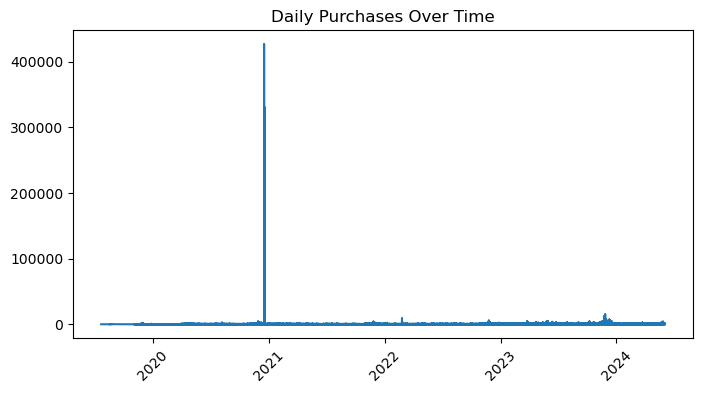

daily_purchases_trend.png has been saved successfully in ../Outputs/Charts/


In [19]:
#Daily Purchase Trend
plt.figure(figsize=(8,4))
plt.plot(mmm_data["DATE_DAY"], mmm_data["ALL_PURCHASES"])
plt.title("Daily Purchases Over Time")
plt.xticks(rotation=45)

# save plot
#plt.savefig("outputs/Charts/daily_purchases_trend.png", dpi=300, bbox_inches="tight
plt.savefig("../Outputs/Charts/daily_purchases_trend.png", dpi=300, bbox_inches="tight")
plt.show()

print("daily_purchases_trend.png has been saved successfully in ../Outputs/Charts/")

In [20]:
print(os.getcwd())

C:\Users\DELL\Desktop\DS-Masters\Semester2\MA_Project\notebooks


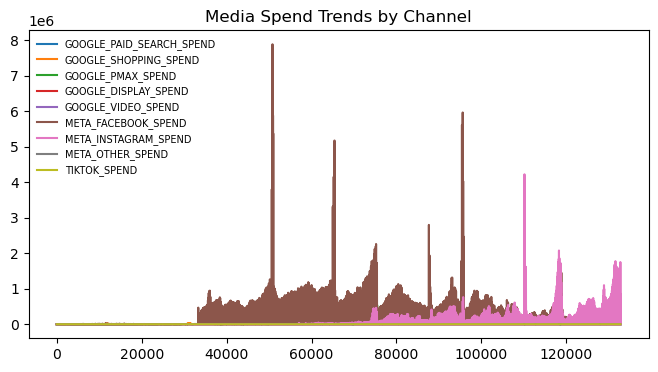

MediaSpend_Trends_by_Channel.png has been saved successfully in ../Outputs/Charts/


In [21]:
#Media Spend Trend
mmm_data[media_spend_cols].plot(figsize=(8,4))
plt.title("Media Spend Trends by Channel")

plt.legend(
    fontsize=7,
    frameon=False,
    loc="upper left"
)

plt.savefig("../Outputs/Charts/MediaSpend_Trends_by_Channel.png", dpi=300, bbox_inches="tight")

plt.show()
print("MediaSpend_Trends_by_Channel.png has been saved successfully in ../Outputs/Charts/")

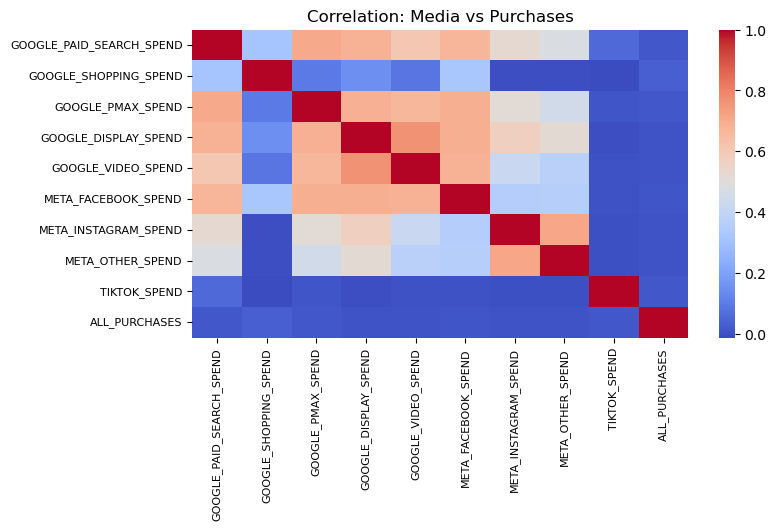

HeatMap_MediaVsPurchases.png has been saved successfully in ../Outputs/Charts/


In [22]:
#Correlation heatmap of Media vs Purchases
plt.figure(figsize=(8,4))
sns.heatmap(
    mmm_data[media_spend_cols + ["ALL_PURCHASES"]].corr(),
    cmap="coolwarm"
)
plt.title("Correlation: Media vs Purchases")
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
#plt.tight_layout() 
#Save Plot
plt.savefig("../Outputs/Charts/HeatMap_MediaVsPurchases.png", dpi=300, bbox_inches="tight")

plt.show()
print("HeatMap_MediaVsPurchases.png has been saved successfully in ../Outputs/Charts/")

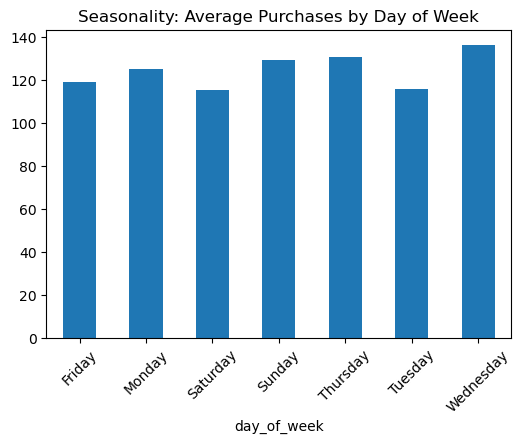

avg_Purchases_DayOfWeek.png has been saved successfully in ../Outputs/Charts/


In [23]:
#Seasonality
mmm_data["day_of_week"] = mmm_data["DATE_DAY"].dt.day_name()

seasonality = mmm_data.groupby("day_of_week")["ALL_PURCHASES"].mean()

seasonality.plot(kind="bar", figsize=(6,4))
plt.title("Seasonality: Average Purchases by Day of Week")
plt.xticks(rotation=45)
#Save Plot
plt.savefig("../Outputs/Charts/avg_Purchases_DayOfWeek.png", dpi=300, bbox_inches="tight")

plt.show()
print("avg_Purchases_DayOfWeek.png has been saved successfully in ../Outputs/Charts/")

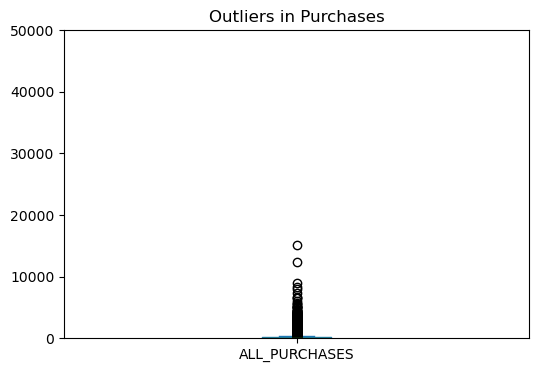

Purchase_Outliers_plot.png has been saved successfully in ../Outputs/Charts/


In [24]:
#Purchase Outliers
mmm_data["ALL_PURCHASES"].plot(kind="box", figsize=(6,4))
plt.ylim(0, 50000)
plt.title("Outliers in Purchases")

#Save Plot
plt.savefig("../Outputs/Charts/Purchase_Outliers_plot.png", dpi=300, bbox_inches="tight")
plt.show()

print("Purchase_Outliers_plot.png has been saved successfully in ../Outputs/Charts/")

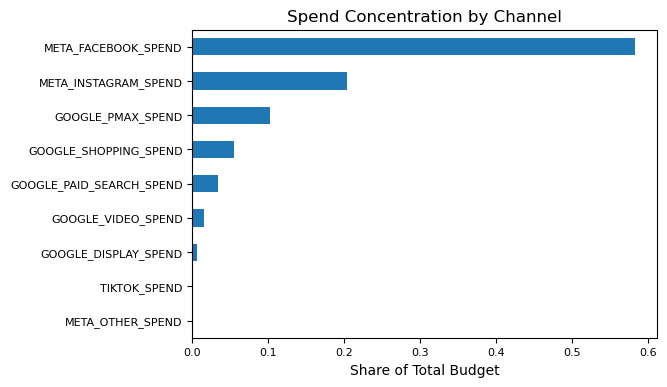

Spend_Concentration_by_Channel.png has been saved successfully in ../Outputs/Charts/


In [25]:
#Spend Concentration by Channel
spend_share = mmm_data[media_spend_cols].sum()
spend_share = spend_share / spend_share.sum()

spend_share.sort_values().plot(kind="barh", figsize=(6,4))
plt.title("Spend Concentration by Channel")
plt.xlabel("Share of Total Budget")
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)

#Save Plot
plt.savefig("../Outputs/Charts/Spend_Concentration_by_Channel.png", dpi=300, bbox_inches="tight")
plt.show()

print("Spend_Concentration_by_Channel.png has been saved successfully in ../Outputs/Charts/")

**TASK 2 - Data Preparation** 

In [26]:
#Aggregrate to daily level
daily_data = (
    mmm_data.groupby("DATE_DAY", as_index=False)
            .sum(numeric_only=True)
)
daily_data

,DATE_DAY,FIRST_PURCHASES,FIRST_PURCHASES_UNITS,FIRST_PURCHASES_ORIGINAL_PRICE,FIRST_PURCHASES_GROSS_DISCOUNT,ALL_PURCHASES,ALL_PURCHASES_UNITS,ALL_PURCHASES_ORIGINAL_PRICE,ALL_PURCHASES_GROSS_DISCOUNT,GOOGLE_PAID_SEARCH_SPEND,...,META_FACEBOOK_IMPRESSIONS,META_INSTAGRAM_IMPRESSIONS,META_OTHER_IMPRESSIONS,TIKTOK_IMPRESSIONS,DIRECT_CLICKS,BRANDED_SEARCH_CLICKS,ORGANIC_SEARCH_CLICKS,EMAIL_CLICKS,REFERRAL_CLICKS,ALL_OTHER_CLICKS
0,2019-07-21,18,26,3.207120e+03,233.137508,19,28,3.299474e+03,2.331375e+02,0.000000,...,0.0,0.0,0.0,0.0,4.0,0.0,2.0,3.0,0.0,2.0
1,2019-07-22,25,33,3.038609e+03,84.538390,25,33,3.038609e+03,8.453839e+01,0.000000,...,0.0,0.0,0.0,0.0,3.0,0.0,16.0,0.0,0.0,12.0
2,2019-07-23,19,24,2.388545e+03,15.750041,19,24,2.388545e+03,1.575004e+01,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,6.0,0.0,2.0,2.0
3,2019-07-24,21,26,2.898102e+03,57.745678,22,27,3.041212e+03,5.774568e+01,0.000000,...,0.0,0.0,0.0,0.0,3.0,0.0,13.0,4.0,0.0,10.0
4,2019-07-25,31,35,5.417889e+03,15.580983,31,35,5.417889e+03,1.558098e+01,0.000000,...,0.0,0.0,0.0,0.0,17.0,0.0,54.0,4.0,12.0,11.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1774,2024-05-29,3165,6668,6.325667e+06,248747.992924,5084,12713,1.293111e+07,1.057085e+06,23997.451163,...,1385020.0,810848.0,5151.0,17804.0,20138.0,10989.0,23336.0,15621.0,28209.0,42501.0
1775,2024-05-30,3015,6920,5.392531e+06,246818.564050,4901,12852,1.187442e+07,9.227262e+05,21215.247349,...,1213575.0,694729.0,3279.0,16583.0,16649.0,11105.0,22025.0,14471.0,30761.0,42703.0
1776,2024-05-31,2938,5925,4.339668e+06,182696.239110,4603,12095,1.080604e+07,1.353137e+06,23119.013351,...,1118997.0,579586.0,2032.0,15459.0,18682.0,12112.0,22231.0,14419.0,23887.0,41805.0
1777,2024-06-01,2930,5416,4.150740e+06,82058.442408,4800,9997,3.363613e+07,8.962230e+06,30694.242915,...,1341131.0,774095.0,2652.0,16075.0,17216.0,10005.0,19089.0,12121.0,39860.0,42695.0


In [27]:
#Save Output in Tables folder
daily_data.to_csv("../Outputs/Tables/daily_data.csv", index=False)
print("daily_data saved in ../Outputs/Tables/")

daily_data saved in ../Outputs/Tables/


In [28]:
mmm_data[
    [
        "FIRST_PURCHASES",
        "ALL_PURCHASES",
        "FIRST_PURCHASES_ORIGINAL_PRICE",
        "ALL_PURCHASES_ORIGINAL_PRICE"
    ]
].describe()

,FIRST_PURCHASES,ALL_PURCHASES,FIRST_PURCHASES_ORIGINAL_PRICE,ALL_PURCHASES_ORIGINAL_PRICE
count,132759.000000,132759.000000,1.327590e+05,1.327590e+05
mean,83.857599,124.536845,6.462644e+04,1.186526e+05
std,345.347969,1496.001905,6.148369e+05,1.211315e+06
min,0.000000,1.000000,0.000000e+00,3.490000e+00
25%,14.000000,19.000000,1.709675e+03,2.546000e+03
50%,33.000000,49.000000,5.262000e+03,7.542000e+03
75%,98.000000,141.000000,1.622458e+04,2.319457e+04
max,96010.000000,426403.000000,7.212126e+07,1.308895e+08


In [29]:
#Select Target variable, My goal is to view Total purchases in order to identify channel
target = "ALL_PURCHASES"

In [30]:
#Media Spend Variable because im focusing on purchase
media_vars = [
    "GOOGLE_PAID_SEARCH_SPEND",
    "GOOGLE_SHOPPING_SPEND",
    "GOOGLE_PMAX_SPEND",
    "META_FACEBOOK_SPEND",
    "META_INSTAGRAM_SPEND",
    "TIKTOK_SPEND"
]
mmm_data[media_vars].head()

,GOOGLE_PAID_SEARCH_SPEND,GOOGLE_SHOPPING_SPEND,GOOGLE_PMAX_SPEND,META_FACEBOOK_SPEND,META_INSTAGRAM_SPEND,TIKTOK_SPEND
0,0.0,86.953533,0.0,0.0,0.0,0.0
1,0.0,87.497234,0.0,0.0,0.0,0.0
2,0.0,85.995222,0.0,0.0,0.0,0.0
3,0.0,95.609758,0.0,0.0,0.0,0.0
4,0.0,73.758269,0.0,0.0,0.0,0.0


In [31]:
#Control Variables

mmm_data["DATE_DAY"] = pd.to_datetime(mmm_data["DATE_DAY"])

#Day of Week
mmm_data["day_of_week"] = mmm_data["DATE_DAY"].dt.dayofweek

#Month
mmm_data["month"] = mmm_data["DATE_DAY"].dt.month

#Quarter
mmm_data["quarter"] = mmm_data["DATE_DAY"].dt.quarter

#Trend
mmm_data = mmm_data.sort_values("DATE_DAY").reset_index(drop=True)
mmm_data["trend"] = range(len(mmm_data))

#promotion
mmm_data["promotions"] = mmm_data["ALL_PURCHASES_GROSS_DISCOUNT"]
#mmm_data[control_vars].head()

In [32]:
control_vars = [
    "TERRITORY_NAME",
    "day_of_week",   
    "month",         # seasonality
    "quarter",       # seasonality
    "trend",
    "promotions"]
mmm_data[control_vars].head()

,TERRITORY_NAME,day_of_week,month,quarter,trend,promotions
0,All Territories,6,7,3,0,233.137508
1,All Territories,0,7,3,1,84.538390
2,All Territories,1,7,3,2,15.750041
3,All Territories,2,7,3,3,57.745678
4,All Territories,3,7,3,4,5.580983


In [33]:
#Time Variables
#Trend View
mmm_data = mmm_data.sort_values("DATE_DAY").reset_index(drop=True)
mmm_data["trend"] = range(len(mmm_data))
#Days of Week
mmm_data["day_of_week"] = mmm_data["DATE_DAY"].dt.dayofweek
#Seasonality
mmm_data["month"] = mmm_data["DATE_DAY"].dt.month
#Quarter
mmm_data["quarter"] = mmm_data["DATE_DAY"].dt.quarter
#Weekend
mmm_data["is_weekend"] = (mmm_data["day_of_week"] >= 5).astype(int)


In [34]:
time_vars = ["DATE_DAY"]
mmm_data[time_vars].head()

,DATE_DAY
0,2019-07-21
1,2019-07-22
2,2019-07-23
3,2019-07-24
4,2019-07-25


In [35]:
#Missing Value Handle
#For Media Variables
mmm_data[media_vars] = mmm_data[media_vars].fillna(0)

#Verify NO missing exist for Media Variable
mmm_data[media_vars].isnull().sum().sort_values(ascending=False)

GOOGLE_PAID_SEARCH_SPEND    0
GOOGLE_SHOPPING_SPEND       0
GOOGLE_PMAX_SPEND           0
META_FACEBOOK_SPEND         0
META_INSTAGRAM_SPEND        0
TIKTOK_SPEND                0
dtype: int64

In [36]:
#Missing Value Handle
#For Control Variables
mmm_data["trend"] = mmm_data["trend"].ffill()
mmm_data["day_of_week"] = mmm_data["day_of_week"].ffill()
mmm_data["month"] = mmm_data["month"].ffill()
mmm_data["quarter"] = mmm_data["quarter"].ffill()
mmm_data["promotions"] = mmm_data["promotions"].fillna(0)
mmm_data["TERRITORY_NAME"] = mmm_data["TERRITORY_NAME"].fillna("Unknown")

#Verify NO missing exist For Control Variables
mmm_data[control_vars].isnull().sum().sort_values(ascending=False)

TERRITORY_NAME    0
day_of_week       0
month             0
quarter           0
trend             0
promotions        0
dtype: int64

In [37]:
#Missing Value Handle
#Time Variable
mmm_data = mmm_data.dropna(subset=["DATE_DAY"])

#Verify NO missing exist For Time Variables
mmm_data[time_vars].isnull().sum().sort_values(ascending=False)

DATE_DAY    0
dtype: int64

In [38]:
#sorting date by time, before Spliting Data in Train and Validation
mmm_data = mmm_data.sort_values("DATE_DAY").reset_index(drop=True)

In [39]:
#unique_dates = mmm_data["DATE_DAY"].sort_values().unique()
#split_date = unique_dates[int(len(unique_dates) * 0.8)]
#split_date

# get unique sorted dates
unique_dates = mmm_data["DATE_DAY"].sort_values().unique()

# define split point (80% train)
split_index = int(len(unique_dates) * 0.8)
split_date = unique_dates[split_index]

print(split_date)

2023-06-13 00:00:00


In [40]:
#Feature set for both train and validation dataset
#features = media_vars + control_vars + time_vars
#target = "ALL_PURCHASES"

In [41]:
#Split into train and Validation
#First 80 into train dataset
train = mmm_data[mmm_data["DATE_DAY"] < split_date]
#Last 20 into validation dataset
validation = mmm_data[mmm_data["DATE_DAY"] >= split_date]

In [42]:
print("Train rows:", train.shape[0])
print("Validation rows:", validation.shape[0])

Train rows: 97425
Validation rows: 35334


In [43]:
train.to_csv("../Outputs/Tables/train_data.csv", index=False)
validation.to_csv("../Outputs/Tables/validation_data.csv", index=False)

print("train and validation dataset has been saved in Outputs/Tables/")

train and validation dataset has been saved in Outputs/Tables/


In [44]:
#Verify no time overlapping
train["DATE_DAY"].max(), validation["DATE_DAY"].min()

(Timestamp('2023-06-12 00:00:00'), Timestamp('2023-06-13 00:00:00'))

In [45]:
#Feature set for both train and validation dataset
features = media_vars + control_vars + time_vars
target = "ALL_PURCHASES"

In [46]:
#Split Train 
X_train = train[features]
y_train = train[target]

#Split Validation
X_val = validation[features]
y_val = validation[target]

In [47]:
#Ensure Train and Validation is splitted
print(X_train.shape, y_train.shape)
print(X_val.shape, y_val.shape)

(97425, 13) (97425,)
(35334, 13) (35334,)


In [48]:
#Ensure Distribution of target
train["ALL_PURCHASES"].describe()
validation["ALL_PURCHASES"].describe()

count    35334.000000
mean       126.441671
std        274.876323
min          1.000000
25%         20.000000
50%         53.000000
75%        137.000000
max      15149.000000
Name: ALL_PURCHASES, dtype: float64

In [49]:
#Media Distibution
train[media_vars].sum()
validation[media_vars].sum()

GOOGLE_PAID_SEARCH_SPEND    1.206055e+07
GOOGLE_SHOPPING_SPEND       1.143171e+07
GOOGLE_PMAX_SPEND           5.188758e+07
META_FACEBOOK_SPEND         1.671923e+08
META_INSTAGRAM_SPEND        1.874717e+08
TIKTOK_SPEND                5.089207e+05
dtype: float64

**TASK 3 - Meridian MMM Model Development**

In [50]:
#final Model Configured
model_data = mmm_data[[target] + media_vars + control_vars + ["DATE_DAY"]]

In [51]:
#model_data = mmm_data[[target] + media_vars + control_vars + ["DATE_DAY"]].copy()

In [52]:
import sys
print(sys.version)

3.13.5 | packaged by Anaconda, Inc. | (main, Jun 12 2025, 16:37:03) [MSC v.1929 64 bit (AMD64)]


In [53]:
#pip uninstall meridian google-meridian -y

In [54]:
#pip install git+https://github.com/google/meridian.git

In [55]:
#pip install meridian google-meridian

In [56]:
#from meridian import Meridian

In [57]:
#import meridian
#print(meridian.__file__)
#print(dir(meridian))

In [58]:
#dir(meridian.model)

In [59]:
#from meridian.spec import Spec
#from meridian.posterior_sampler import PosteriorSampler

#spec = Spec(
 #   target="ALL_PURCHASES",
  #  date_column="DATE_DAY",
   # media_channels=media_channels,
   # control_columns=control_columns
#)

In [60]:
#AdStock
def adstock(x, decay=0.6):
    y = np.zeros(len(x))
    y[0] = x.iloc[0]
    for i in range(1, len(x)):
        y[i] = x.iloc[i] + decay * y[i-1]
    return y

for col in media_vars:
    model_data.loc[:, col] = adstock(model_data[col].fillna(0))

In [61]:
#Hill Function
def hill(x, alpha=1.5, gamma=0.5):
    return (x ** alpha) / (gamma ** alpha + x ** alpha)

for col in media_vars:
    model_data.loc[:, col] = hill(model_data[col])

In [62]:
#Train the MMM model
from sklearn.linear_model import Ridge

X = model_data[media_vars + control_vars]

X = pd.get_dummies(
    model_data[media_vars + control_vars],
    drop_first=True
)


y = model_data[target]

model = Ridge(alpha=1.0)
model.fit(X, y)

#y_pred = model.predict(X)


Ridge()

In [63]:
#y_pred = model.predict(X)

In [64]:
#Channel contribution (Attribution)
contribution = pd.DataFrame({
    "channel": X.columns,
    "impact": model.coef_
}).sort_values(by="impact", ascending=False)

round(contribution,3)

,channel,impact
3,META_FACEBOOK_SPEND,79.738
1,GOOGLE_SHOPPING_SPEND,39.659
27,TERRITORY_NAME_UK,17.252
7,month,10.306
5,TIKTOK_SPEND,8.033
0,GOOGLE_PAID_SEARCH_SPEND,7.265
14,TERRITORY_NAME_Denmark,6.515
9,trend,0.000
10,promotions,0.000
6,day_of_week,-0.081


In [65]:
#Save Channel Contributions
contribution.to_csv("../outputs/Tables/channel_contribution.csv", index=False)

print("Channel contributions are saved in ../Outputs/Tables/")

Channel contributions are saved in ../Outputs/Tables/


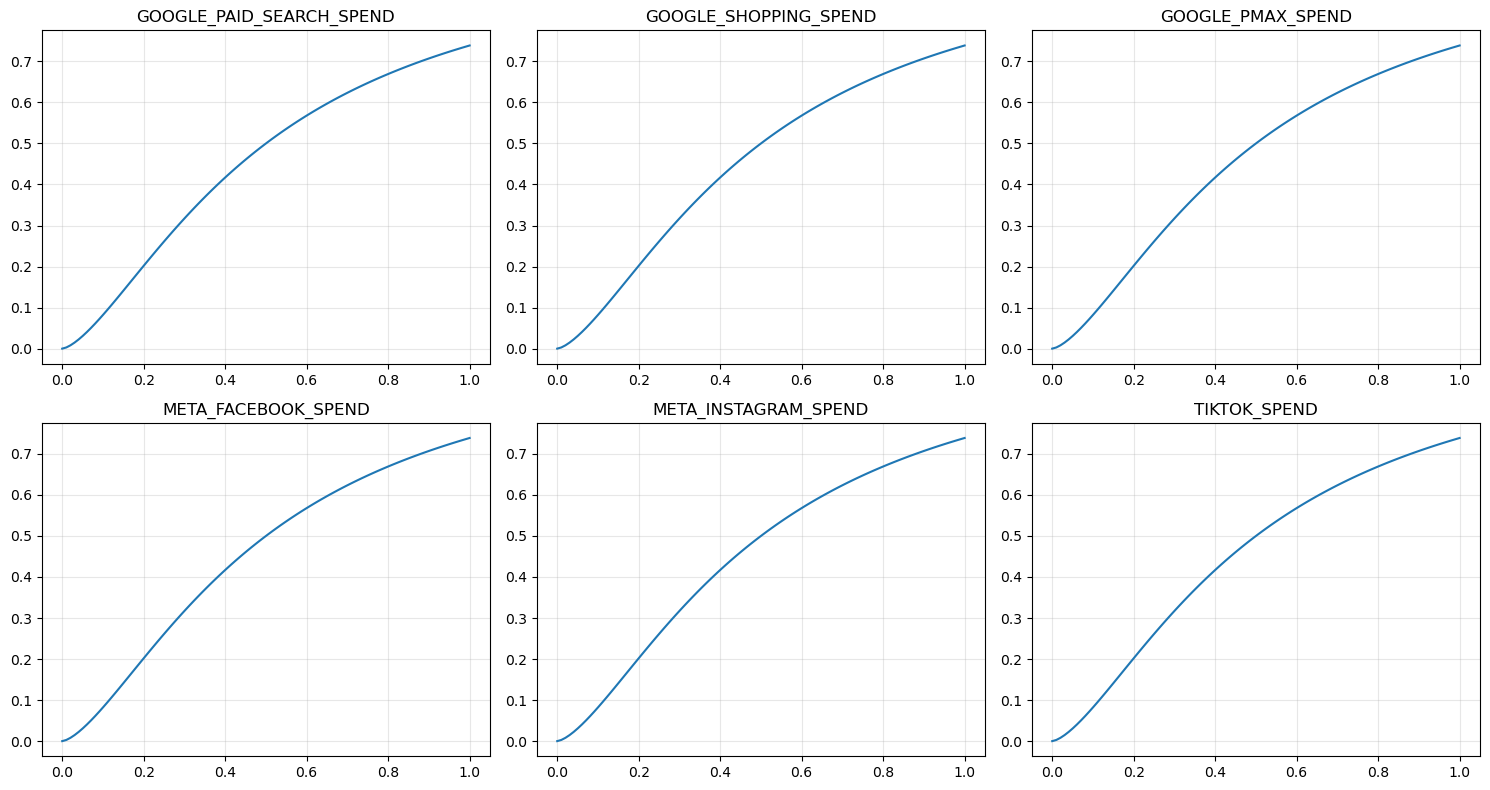

SaturationCurve_Channel_Spend.png has been saved successfully in ../Outputs/Charts/


In [66]:
#Saturation Curve
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()  # to convert 2x3 array into a 1D list

for i, col in enumerate(media_vars):
    x = np.linspace(0, model_data[col].max(), 100)
    y = hill(x)

    axes[i].plot(x, y)
    axes[i].set_title(col)
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
#Save plot
plt.savefig("../Outputs/Charts/SaturationCurve_Channel_Spend.png", dpi=300, bbox_inches="tight")

plt.show()

print("SaturationCurve_Channel_Spend.png has been saved successfully in ../Outputs/Charts/")

In [67]:
X = model_data[media_vars + control_vars]
X = pd.get_dummies(
    model_data[media_vars + control_vars],
    drop_first=True
)
y = model_data[target]

model = Ridge(alpha=1.0)
model.fit(X, y)
#y_pred = model.predict(X)

Ridge()

In [68]:
# actual predictions
y_actual_Pred = model.predict(X)
#y_pred = model.predict(X)

# no marketing
X_cf = X.copy()
X_cf[media_vars] = 0

y_no_media = model.predict(X_cf)

# incrementality
incrementality = y_actual_Pred - y_no_media

In [69]:
print(X.dtypes)

GOOGLE_PAID_SEARCH_SPEND      float64
GOOGLE_SHOPPING_SPEND         float64
GOOGLE_PMAX_SPEND             float64
META_FACEBOOK_SPEND           float64
META_INSTAGRAM_SPEND          float64
TIKTOK_SPEND                  float64
day_of_week                     int32
month                           int32
quarter                         int32
trend                           int64
promotions                    float64
TERRITORY_NAME_Australia         bool
TERRITORY_NAME_Austria           bool
TERRITORY_NAME_Canada            bool
TERRITORY_NAME_Denmark           bool
TERRITORY_NAME_France            bool
TERRITORY_NAME_Germany           bool
TERRITORY_NAME_Hong Kong         bool
TERRITORY_NAME_Ireland           bool
TERRITORY_NAME_Italy             bool
TERRITORY_NAME_Japan             bool
TERRITORY_NAME_Netherlands       bool
TERRITORY_NAME_New Zealand       bool
TERRITORY_NAME_Norway            bool
TERRITORY_NAME_Spain             bool
TERRITORY_NAME_Sweden            bool
TERRITORY_NA

In [70]:
#Bayesian Estimation
from sklearn.linear_model import BayesianRidge

bayes_model = BayesianRidge()
#bayes_model.fit(X, y)
bayes_model.fit(X, y)

#y_bayes_pred = bayes_model.predict(X)

BayesianRidge()

In [71]:
#Mean Predictions
y_bayes_pred = bayes_model.predict(X)
y_bayes_pred

array([124.47796803, 124.90963383, 124.80086727, ...,  51.28105695,
       145.17517927, 169.29963377])

In [72]:
#Check row count
#print(X_bayes.shape)
#print(y_bayes.shape)

In [73]:
#Metric Evaluation
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_percentage_error

r2 = r2_score(y, y_actual_Pred)
rmse = np.sqrt(mean_squared_error(y, y_actual_Pred))
mape = mean_absolute_percentage_error(y, y_actual_Pred) * 100

print(f"R²   : {r2:.4f}")
print(f"RMSE : {rmse:.2f}")
print(f"MAPE : {mape:.2f}%")

R²   : 0.0029
RMSE : 1493.85
MAPE : 384.35%


**TASK 4 — ROI and Marginal ROI Analysis**

In [74]:
#incremental contribution by channel
channel_incrementality = {}

for channel in media_vars:
    X_cf = X.copy()

    # Remove only this channel
    X_cf[channel] = 0

    #y_cf = model.predict(X_cf.values)
    y_cf = model.predict(X_cf)

    #channel_incrementality[channel] = y_actual_Pred - y_cf
    channel_incrementality[channel] = (y_actual_Pred - y_cf).sum()

In [75]:
# Total incremental sales by channel
incremental_sales = {
    ch: channel_incrementality[ch].sum()
    for ch in media_vars
}

In [76]:
#Total Spend 
total_spend = {
    ch: X[ch].sum()
    for ch in media_vars
}

In [77]:
#ROI 
roi_df = pd.DataFrame({
    "Channel": media_vars,
    "Incremental Sales": [incremental_sales[ch] for ch in media_vars],
    "Spend": [total_spend[ch] for ch in media_vars]
})

roi_df["ROI"] = roi_df["Incremental Sales"] / roi_df["Spend"]

print(roi_df)

                    Channel  Incremental Sales          Spend        ROI
0  GOOGLE_PAID_SEARCH_SPEND       9.634695e+05  132611.604735   7.265348
1     GOOGLE_SHOPPING_SPEND       5.253438e+06  132465.782731  39.658831
2         GOOGLE_PMAX_SPEND      -2.310035e+06   92952.897341 -24.851670
3       META_FACEBOOK_SPEND       1.052993e+07  132057.026834  79.737759
4      META_INSTAGRAM_SPEND      -7.036374e+06  107573.020433 -65.410211
5              TIKTOK_SPEND       2.577495e+05   32086.657239   8.032917


In [78]:
#mROI
# Marginal ROI
mroi = {}

# Base prediction
#y_base = model.predict(X.values)
#y_base = model.predict(X) 

X_base = X.copy()
X_base[media_vars] = 0

y_base = model.predict(X_base)
y_full = model.predict(X)

for channel in media_vars:

    X_new = X.copy()
    X_new[channel] *= 1.01

    y_new = model.predict(X_new)

    delta_sales = (y_new - y_full).sum()

    delta_spend = (X_new[channel] - X[channel]).sum()

    mroi[channel] = delta_sales / delta_spend

In [79]:
roi_df["mROI"] = [mroi[ch] for ch in media_vars]

roi_df = roi_df[["Channel", "Incremental Sales", "Spend", "ROI", "mROI"]]
roi_df

,Channel,Incremental Sales,Spend,ROI,mROI
0,GOOGLE_PAID_SEARCH_SPEND,9.634695e+05,132611.604735,7.265348,7.265348
1,GOOGLE_SHOPPING_SPEND,5.253438e+06,132465.782731,39.658831,39.658831
2,GOOGLE_PMAX_SPEND,-2.310035e+06,92952.897341,-24.851670,-24.851670
3,META_FACEBOOK_SPEND,1.052993e+07,132057.026834,79.737759,79.737759
4,META_INSTAGRAM_SPEND,-7.036374e+06,107573.020433,-65.410211,-65.410211
5,TIKTOK_SPEND,2.577495e+05,32086.657239,8.032917,8.032917


In [80]:
#Channels Efficiency
roi_df["Efficiency_Class"] = roi_df["ROI"].apply(
    lambda x: "High efficiency (Under-invested)" if x > 10
    else ("Medium efficiency" if x > 0 else "Low efficiency (Over-invested)")
)

In [81]:
roi_df.sort_values("ROI", ascending=False)

,Channel,Incremental Sales,Spend,ROI,mROI,Efficiency_Class
3,META_FACEBOOK_SPEND,1.052993e+07,132057.026834,79.737759,79.737759,High efficiency (Under-invested)
1,GOOGLE_SHOPPING_SPEND,5.253438e+06,132465.782731,39.658831,39.658831,High efficiency (Under-invested)
5,TIKTOK_SPEND,2.577495e+05,32086.657239,8.032917,8.032917,Medium efficiency
0,GOOGLE_PAID_SEARCH_SPEND,9.634695e+05,132611.604735,7.265348,7.265348,Medium efficiency
2,GOOGLE_PMAX_SPEND,-2.310035e+06,92952.897341,-24.851670,-24.851670,Low efficiency (Over-invested)
4,META_INSTAGRAM_SPEND,-7.036374e+06,107573.020433,-65.410211,-65.410211,Low efficiency (Over-invested)


In [82]:
roi_df.to_csv("../Outputs/Tables/channel_Efficieny.csv", index=False)
print("channel_Efficieny.csv has been saved in ../Outputs/Tables/")

channel_Efficieny.csv has been saved in ../Outputs/Tables/


In [83]:
print(X.dtypes)

GOOGLE_PAID_SEARCH_SPEND      float64
GOOGLE_SHOPPING_SPEND         float64
GOOGLE_PMAX_SPEND             float64
META_FACEBOOK_SPEND           float64
META_INSTAGRAM_SPEND          float64
TIKTOK_SPEND                  float64
day_of_week                     int32
month                           int32
quarter                         int32
trend                           int64
promotions                    float64
TERRITORY_NAME_Australia         bool
TERRITORY_NAME_Austria           bool
TERRITORY_NAME_Canada            bool
TERRITORY_NAME_Denmark           bool
TERRITORY_NAME_France            bool
TERRITORY_NAME_Germany           bool
TERRITORY_NAME_Hong Kong         bool
TERRITORY_NAME_Ireland           bool
TERRITORY_NAME_Italy             bool
TERRITORY_NAME_Japan             bool
TERRITORY_NAME_Netherlands       bool
TERRITORY_NAME_New Zealand       bool
TERRITORY_NAME_Norway            bool
TERRITORY_NAME_Spain             bool
TERRITORY_NAME_Sweden            bool
TERRITORY_NA

**TASK 5 - SHAP Explainability**

In [84]:
!pip install shap

In [85]:
#Create SHAP values
import shap

explainer = shap.Explainer(model, X)
shap_values = explainer(X)

Background dataset has 132759 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=132759 when initializing the masker.


In [86]:
print(shap_values.values.dtype)
print(shap_values.values.shape)

object
(132759, 29)


In [87]:
#Convert dtype to float
shap_matrix = np.array(shap_values.values.tolist(), dtype=np.float64)

print(shap_matrix.dtype)
print(shap_matrix.shape)

float64
(132759, 29)


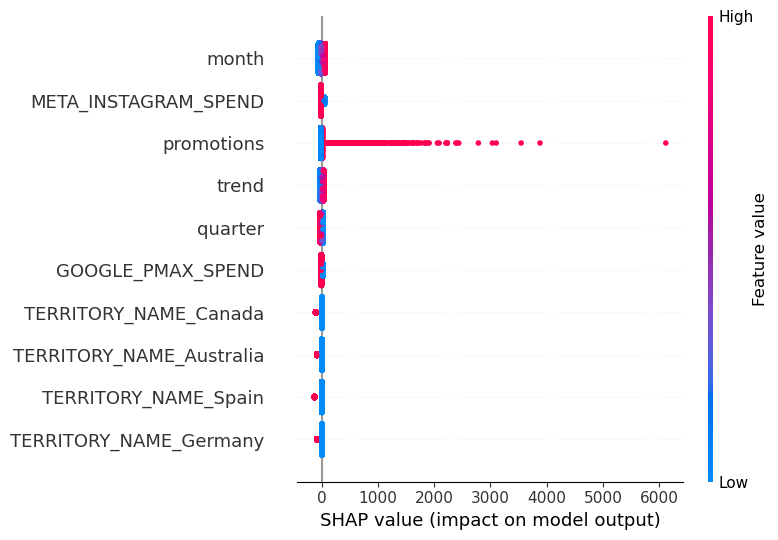

SHAP summary plot saved successfully in ../Outputs/Charts/


In [88]:
#Shap Summary Plot
shap.summary_plot(shap_matrix, X, max_display=10, show=False,plot_type="dot")   # ensures matplotlib backend

# get current figure
fig = plt.gcf()

#Save Plot
plt.savefig("../Outputs/Charts/shap_summary.png", dpi=300, bbox_inches="tight")

plt.show()

print("SHAP summary plot saved successfully in ../Outputs/Charts/")

In [89]:
#Feature Ranking
shap_importance = pd.DataFrame({
    "Feature": X.columns,
    "SHAP_Importance": np.abs(shap_values.values).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    "SHAP_Importance",
    ascending=False
)

shap_importance

,Feature,SHAP_Importance
7,month,31.359149
4,META_INSTAGRAM_SPEND,20.752083
10,promotions,17.220417
9,trend,14.691783
8,quarter,14.383239
2,GOOGLE_PMAX_SPEND,10.736854
13,TERRITORY_NAME_Canada,9.405482
11,TERRITORY_NAME_Australia,5.510433
24,TERRITORY_NAME_Spain,4.851826
16,TERRITORY_NAME_Germany,4.520107


In [90]:
#Save Shap Feature Ranking
contribution.to_csv("../outputs/Tables/shap_Feature_Ranking.csv", index=False)
print("Shap_Feature_Ranking.csv is saved in ../Outputs/Tables/")

Shap_Feature_Ranking.csv is saved in ../Outputs/Tables/


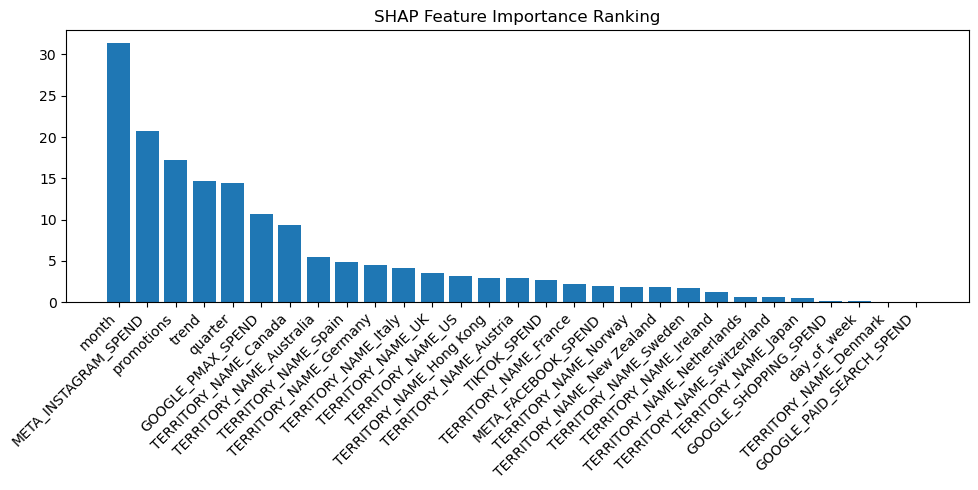

In [91]:
#Bar chart for Shap Feature Importance Ranking
plt.figure(figsize=(10,5))
plt.bar(shap_importance["Feature"], shap_importance["SHAP_Importance"])
plt.xticks(rotation=45, ha="right")
plt.title("SHAP Feature Importance Ranking")
plt.tight_layout()
plt.show()

In [92]:
#MMM has only Media Channel, so for shap media filter is needed
media_shap = shap_importance[
    shap_importance["Feature"].isin(media_vars)
].copy()

media_shap

,Feature,SHAP_Importance
4,META_INSTAGRAM_SPEND,20.752083
2,GOOGLE_PMAX_SPEND,10.736854
5,TIKTOK_SPEND,2.644276
3,META_FACEBOOK_SPEND,1.986739
1,GOOGLE_SHOPPING_SPEND,0.199095
0,GOOGLE_PAID_SEARCH_SPEND,0.008933


In [93]:
#Top 3 Media Features
media_shap = shap_importance[
    shap_importance["Feature"].isin(media_vars)
].copy()

top3_media = media_shap.sort_values(
    by="SHAP_Importance",
    ascending=False
).head(3)["Feature"].values

print(top3_media)

['META_INSTAGRAM_SPEND' 'GOOGLE_PMAX_SPEND' 'TIKTOK_SPEND']


In [94]:
print(shap_values.values.shape)
print(X.shape)

(132759, 29)
(132759, 29)


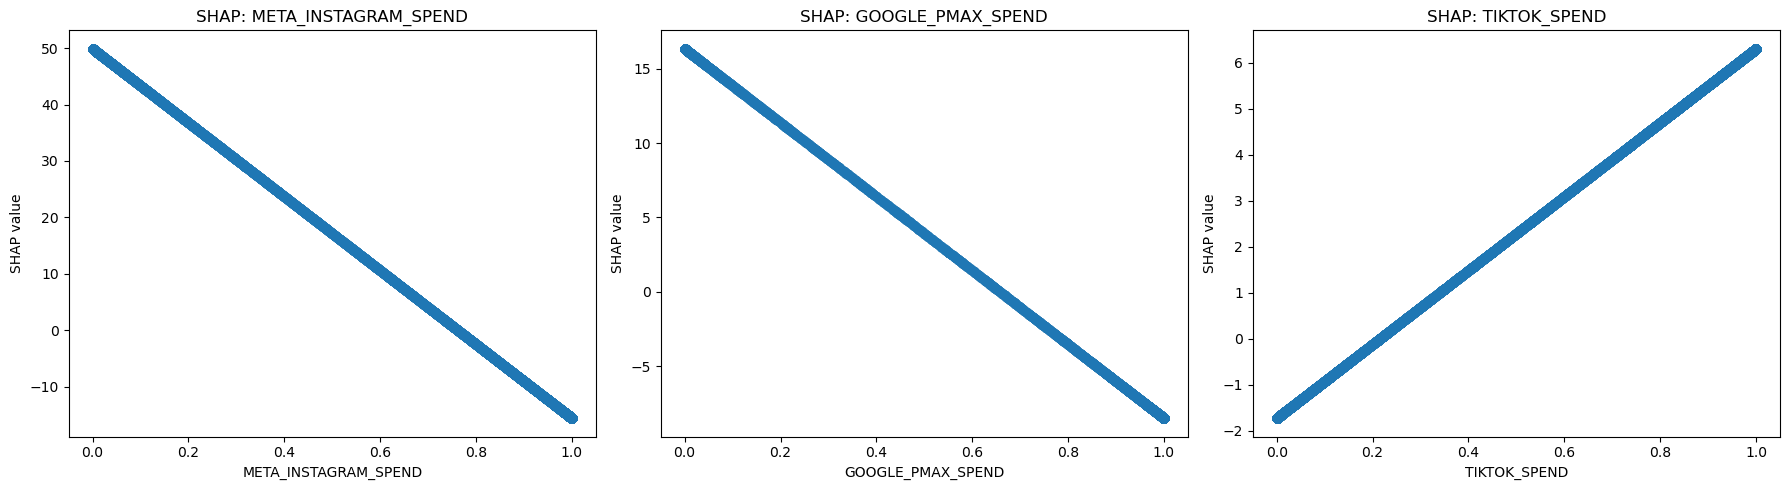

In [95]:
#Top 3 Dependency Plot for Media Vars

#1 row 3 columns
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(top3_media):

    idx = list(X.columns).index(col)

    x = X[col]
    y = shap_values.values[:, idx]

    axes[i].scatter(x, y, alpha=0.6)

    axes[i].set_title(f"SHAP: {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("SHAP value")

plt.tight_layout()

plt.savefig(
    "../Outputs/Charts/Top3_MediaVar_Dependency_Plots.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [96]:
# MMM contribution
mmm_contribution = contribution.copy()

mmm_contribution.columns = [
    "Feature",
    "MMM_Contribution"
]

In [97]:
# Compare SHAP vs MMM
comparison = media_shap.merge(
    mmm_contribution,
    on="Feature",
    how="left"
)

comparison = comparison.sort_values(
    by="SHAP_Importance",
    ascending=False
)

comparison

,Feature,SHAP_Importance,MMM_Contribution
0,META_INSTAGRAM_SPEND,20.752083,-65.410211
1,GOOGLE_PMAX_SPEND,10.736854,-24.851670
2,TIKTOK_SPEND,2.644276,8.032917
3,META_FACEBOOK_SPEND,1.986739,79.737759
4,GOOGLE_SHOPPING_SPEND,0.199095,39.658831
5,GOOGLE_PAID_SEARCH_SPEND,0.008933,7.265348


In [98]:
comparison.to_csv(
    "../Outputs/Tables/shap_vs_mmm.csv",
    index=False
)

print("SHAP vs MMM comparison saved in ../Outputs/Tables/shap_vs_mmm.cs")

SHAP vs MMM comparison saved in ../Outputs/Tables/shap_vs_mmm.cs


In [99]:
#For comparison graph text are overwritting
!pip install adjustText

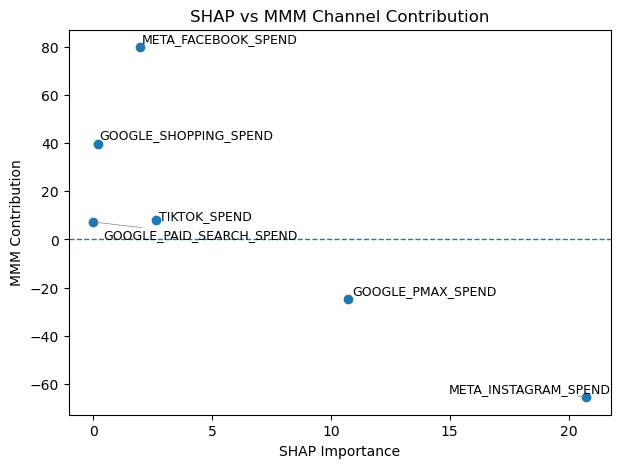

Shap_vs_MMM_Channel_Contribution.png has been saved successfully in ../Outputs/Charts/


In [100]:
#Plot for Shap and MMM
from adjustText import adjust_text

plt.figure(figsize=(7,5))

plt.scatter(
    comparison["SHAP_Importance"],
    comparison["MMM_Contribution"]
)

texts = []

for i, row in comparison.iterrows():
    texts.append(
        plt.text(
            row["SHAP_Importance"],
            row["MMM_Contribution"],
            row["Feature"],
            fontsize=9
        )
    )

adjust_text(texts, arrowprops=dict(arrowstyle="->", color="gray", lw=0.5))

plt.axhline(0, linestyle="--", linewidth=1)
plt.xlabel("SHAP Importance")
plt.ylabel("MMM Contribution")
plt.title("SHAP vs MMM Channel Contribution")

#Save plot
plt.savefig("../Outputs/Charts/Shap_vs_MMM_Channel_Contribution.png", dpi=300, bbox_inches="tight")

plt.show()
print("Shap_vs_MMM_Channel_Contribution.png has been saved successfully in ../Outputs/Charts/")

**TASK 6 - Marketing Investment Scenario Simulation**

In [101]:
#Predict current purchases using fitted model.
#baseline_pred = model.predict(X)

#baseline_purchases = baseline_pred.sum()
baseline_purchases = y_actual_Pred.sum()

print("Baseline Purchases:", baseline_purchases)

Baseline Purchases: 16533387.0


In [102]:
#Scenario 1
#Equal Allocation (+20% Total Spend)
X_equal = X.copy()

for col in media_vars:
    X_equal[col] *= 1.20

pred_equal = model.predict(X_equal)

incremental_purchases_equal = pred_equal.sum() - baseline_purchases

extra_spend_equal = (X_equal[media_vars].sum().sum()
                     - X[media_vars].sum().sum())

roi_equal = incremental_purchases_equal / extra_spend_equal
round(roi_equal,3)

np.float64(12.161)

In [103]:
incremental_revenue_equal = incremental_purchases_equal

In [104]:
#Scenario 2: mROI Optimized (+50% on Best Channel)

#from previous camparison graph, best channel (moderate shap and high positive MMM) found
best_channel = "META_FACEBOOK_SPEND"

X_mroi = X.copy()

X_mroi[best_channel] *= 1.50

pred_mroi = model.predict(X_mroi)

incremental_purchases_mroi = pred_mroi.sum() - baseline_purchases

extra_spend_mroi = (
    X_mroi[best_channel].sum()
    - X[best_channel].sum()
)

roi_mroi = incremental_purchases_mroi / extra_spend_mroi
round(roi_mroi,3)

np.float64(79.738)

In [105]:
incremental_revenue_mroi = incremental_purchases_mroi

In [106]:
#Scenario 3: Saturation Awareness (-30%)

#from previous camparison graph, saturated channels (mROI is less than 0) found
saturated_channels = [
    "GOOGLE_PMAX_SPEND",
    "META_INSTAGRAM_SPEND"
]

X_saturated = X.copy()

for col in saturated_channels:
    X_saturated[col] *= 0.70

pred_saturated = model.predict(X_saturated)

incremental_purchases_sat = pred_saturated.sum() - baseline_purchases

saved_spend = (X[media_vars].sum().sum()- X_saturated[media_vars].sum().sum())

roi_saturation = incremental_purchases_sat / abs(saved_spend)
round(roi_saturation,3)

np.float64(46.609)

In [107]:
incremental_revenue_sat = incremental_purchases_sat

In [108]:
#Scenario 4: Random +10% on Half Channels
import random

#Half Randomly Selected
random.seed(100)

half_channels = random.sample(
    media_vars,
    len(media_vars)//2
)

X_rand = X.copy()

for col in half_channels:
    X_rand[col] *= 1.10

pred_rand = model.predict(X_rand)

incremental_purchases_rand = pred_rand.sum() - baseline_purchases

extra_spend_rand = (
    X_rand[media_vars].sum().sum()
    - X[media_vars].sum().sum()
)

roi_random = incremental_purchases_rand / extra_spend_rand
round(roi_random,3)

np.float64(23.507)

In [109]:
incremental_revenue_rand=incremental_purchases_rand

In [110]:
#All Scenario Camparison Table
results = pd.DataFrame({
    "Scenario":[
        "Equal allocation",
        "mROI optimized",
        "Saturation aware",
        "Random allocation"
    ],

    "Incremental Purchases":[
        incremental_purchases_equal,
        incremental_purchases_mroi,
        incremental_purchases_sat,
        incremental_purchases_rand
    ],

    "Incremental Revenue":[
        incremental_revenue_equal,
        incremental_revenue_mroi,
        incremental_revenue_sat,
        incremental_revenue_rand
    ],

    "ROI":[
        roi_equal,
        roi_mroi,
        roi_saturation,
        roi_random
    ]
})
results

,Scenario,Incremental Purchases,Incremental Revenue,ROI
0,Equal allocation,1.531636e+06,1.531636e+06,12.160725
1,mROI optimized,5.264966e+06,5.264966e+06,79.737759
2,Saturation aware,2.803923e+06,2.803923e+06,46.609480
3,Random allocation,8.746995e+05,8.746995e+05,23.507373


In [113]:
results

,Scenario,Incremental Purchases,Incremental Revenue,ROI
0,Equal allocation,1.531636e+06,1.531636e+06,12.160725
1,mROI optimized,5.264966e+06,5.264966e+06,79.737759
2,Saturation aware,2.803923e+06,2.803923e+06,46.609480
3,Random allocation,8.746995e+05,8.746995e+05,23.507373


In [111]:
#Save Scenario Results
results.to_csv("../outputs/Tables/all_ScenarioResults.csv", index=False)
print("all_ScenarioResults are saved in ../Outputs/Tables/")

all_ScenarioResults are saved in ../Outputs/Tables/


In [112]:
#With all outputs visible